---
#**ENTREGA PARCIAL**
---



**Título:**
> "Variabilidad interanual de la temperatura del aire y de la superficie terrestre en Piura (2020-2025) y su relación con El Niño y La Niña"


**Integrantes:**
>* Alexandra Caballero (20222790)
>* Angele Pérez (20201988)
>* Karla Montoya (20196066)






## **Descripción del proyecto**

> El proyecto analiza cómo varió la temperatura en el departamento de Piura entre 2020 y 2025 y si esas variaciones coinciden en el tiempo con las fases de El Niño y La Niña. La temperatura se toma de dos productos procesados en Google Earth Engine: la temperatura del aire a 2 m del reanálisis ERA5-Land y la temperatura de la superficie terrestre (LST, por sus siglas en inglés) de Landsat 8 y 9. Las fases se siguen con el Índice Oceánico El Niño (ONI) del Pacífico central y el Índice Costero El Niño (ICEN) del mar frente a Perú y Ecuador.


**Objetivos:**

Objetivo general: Analizar la variación de la temperatura en Piura entre 2020 y 2025 y su relación con las fases de El Niño y La Niña.

Objetivos específicos:


1.   Comparar el comportamiento de la temperatura de ERA5-Land y de Landsat 8 y 9.
2. Evaluar la correlación entre las anomalías de temperatura y los índices ONI e ICEN.



Hipótesis exploratoria:

Se espera que la temperatura en Piura esté por encima de su promedio en los meses con El Niño y por debajo en los meses con La Niña. Esta expectativa se basa en lo ocurrido durante El Niño costero de 2017. En febrero y marzo de ese año, las temperaturas máximas y mínimas del aire en la costa peruana estuvieron entre 1,0 y 2,3 °C por encima de lo normal (Takahashi et al., 2018).



**Variables a analizar:**

1.   Temperatura (utilizando dos fuentes):


      *   ERA5-Land: temperatura del aire a 2 metros, como promedio mensual de datos horarios en celdas de unos 9 kilómetros.
      *   Landsat 8 y 9: temperatura de la superficie terrestre (LST) con píxeles de 30 metros.   

      *   Como una mide el aire y la otra la superficie, sus valores no coinciden. Por eso se compararán sus comportamientos a lo largo de cada año en el rango 2020-2025.




2.   Condición del El Niño-Oscilación del Sur (usando dos índices):

      *   Índice Oceánico El Niño (ONI): promedio de tres meses de la anomalía de temperatura superficial en el Pacífico Central (región Niño 3.4). Un valor de +0,5 °C o más indica El Niño y uno de −0,5 °C o menos indica La Niña (CPC, s/f).
      

      *   Índice Costero El Niño (ICEN): la misma medida para el mar frente a Perú y Ecuador (región Niño 1+2). Las condiciones cálidas empiezan cuando se supera +0,5 °C y las frías cuando baja de −0,7 °C (ENFEN, 2024).

**Área de estudio:**
> El área de estudio es el departamento de Piura, en el noroeste del Perú. Tiene 35 892 km², limita con Tumbes, Ecuador, Cajamarca, Lambayeque y el océano Pacífico. Su relieve va del desierto de Sechura, con depresiones bajo el nivel del mar, a cerca de 3900 m en la cordillera Occidental (Rodríguez et al., 2011).

> Piura se eligió por su exposición a El Niño. El mar frente a su costa forma parte de la región Niño 1+2. Su llanura costera es árida en años normales, pero durante El Niño recibe lluvias intensas asociadas al calentamiento del mar cercano (Takahashi, 2004). En marzo de 2017, durante El Niño costero, el caudal mensual del río Piura llegó a unas seis veces su media climatológica y la ciudad se inundó el 25 de ese mes (Yglesias-González et al., 2023). En febrero y marzo de ese año, las anomalías de temperatura máxima y mínima del aire en la costa peruana fueron de +1,0 a +2,3 °C (Takahashi et al., 2018). En 2023, otro evento costero dejó bajo el agua parte del desierto de Sechura (Peng et al., 2024). Con estos antecedentes cabe esperar una señal de ENSO en la temperatura del departamento.

**Periodo temporal:**

El periodo va de enero de 2020 a diciembre de 2025 (72 meses). Se cierra en 2025 porque es el último año completo en todas las series. En esos seis años hubo fases opuestas de ENSO. Según el ONI, La Niña predominó desde agosto-octubre de 2020 hasta diciembre-febrero de 2022-2023, con una breve pausa a mediados de 2021. Luego El Niño se extendió de abril-junio de 2023 a marzo-mayo de 2024, con un máximo de +2,0 °C en noviembre-enero de 2023-2024 (CPC, s/f). Frente a la costa, El Niño costero se desarrolló entre inicios de 2023 y el verano de 2024 (Instituto Geofísico del Perú, 2024). Entre mediados de 2024 y fines de 2025 el ONI osciló entre -0,6 y +0,4 °C, con condiciones neutras o de enfriamiento débil.

## **Exploración preliminar**

>Exploración preliminar de los datos, con una visualización básica (mapas, series de
tiempo según aplique) que confirme que los datos cubren el área y periodo de
interés.

### Pasos Previos: Para emplear catálogos de GEE

In [ ]:
# Instalamos librerías necesarias, además de rioxarray y cartopy
!pip install -q rioxarray cartopy

import ee
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import rioxarray

from google.colab import drive # Importamos el módulo para conectar con Google Drive
drive.mount('/content/drive') # Montamos la unidad de Drive en nuestro entorno de Colab

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Autenticación
ee.Authenticate(auth_mode='notebook')

True

In [ ]:
# Iniciamos el proyecto
PROJECT_ID = 'nombre-geocomputacion' #Esta parte se cambia por el ID del proyecto creado
ee.Initialize(project=PROJECT_ID)

### Variable 1.1. : Temperatura del aire a 2mt - ERA5 Land

In [ ]:
# 1 Definimos el recuadro (Bounding Box) mediante coordenadas [lon_min, lat_min, lon_max, lat_max]
bbox_piura = [-81.5, -6.5, -79, -4] # Coordenadas geográficas límite de Piura
roi_bbox_era5 = ee.Geometry.Rectangle(bbox_piura) # Creamos un polígono

# 2 Cargamos la colección mensual de ERA5-Land, filtramos por nuestra área y periodo, y seleccionamos la banda t2m
era5_mensual = (ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY_AGGR")
                .filterBounds(roi_bbox_era5)
                .filterDate("2020-01-01", "2025-12-31")
                .select("temperature_2m"))

# 3 Función para extraer el promedio espacial de la temperatura por cada imagen mensual
def reducir_region_bbox_era5(img):
    # reduceRegion promedia los valores de todos los píxeles que caen dentro del BBox
    mean_val = img.reduceRegion(
        reducer=ee.Reducer.mean(), # Usamos el reductor de promedio (media espacial)
        geometry=roi_bbox_era5, # Definimos la geometría sobre la cual calcular el promedio
        scale=11132, # Resolución nativa aproximada de ERA5-Land (~9km) para realizar el cálculo
        maxPixels=1e9 # Aumentamos el límite de píxeles procesables
    ).get("temperature_2m") # Extrae específicamente el valor numérico calculado

    # Retornamos un Feature (entidad) que almacena la fecha y el valor térmico en Kelvin
    return ee.Feature(None, {
        'date': img.date().format('YYYY-MM-dd'), # Formateamos la fecha de la imagen como texto (Año-Mes-Día)
        't2m_K': mean_val # Guardamos el valor promedio obtenido en grados Kelvin
    })

# 4 Mapeamos la función sobre toda la colección y extraemos los resultados hacia un DataFrame
# .map() aplica la función a cada imagen, .filter() quita resultados nulos, y .getInfo() extrae los datos de la nube a Python
features_era5 = era5_mensual.map(reducir_region_bbox_era5).filter(ee.Filter.notNull(['t2m_K'])).getInfo()['features']
df_era5 = pd.DataFrame([f['properties'] for f in features_era5]) # Convertimos la lista de diccionarios en un DataFrame de Pandas

# 5 Conversión de unidades (Kelvin a Celsius) y extracción de variables temporales para el gráfico
df_era5['fecha'] = pd.to_datetime(df_era5['date']) # Convierte la columna 'date' (texto) a un formato de tiempo real (datetime)
df_era5['valor_C_era5'] = df_era5['t2m_K'] - 273.15 # Convierte la temperatura de Kelvin a Celsius restando 273.15
df_era5['año'] = df_era5['fecha'].dt.year # Extrae únicamente el año de la fecha y lo guarda en una nueva columna
df_era5['mes'] = df_era5['fecha'].dt.month # Extrae únicamente el mes de la fecha para usarlo en el eje X

# 6 Reestructuramos los datos con pivot: meses en el eje X, y cada año será una columna independiente
df_pivot_era5 = df_era5.pivot(index='mes', columns='año', values='valor_C_era5')

# 7 Exportamos el DataFrame en crudo a Google Drive - quitar los numerales para descomentar
# Guardamos el archivo CSV específico de ERA5, omitiendo el índice automático de las filas (index=False)
df_era5.to_csv('/content/drive/My Drive/ERA5_T2M_Piura.csv', index=False)
print("Archivo crudo ERA5 guardado exitosamente en Google Drive.")


Archivo crudo ERA5 guardado exitosamente en Google Drive.


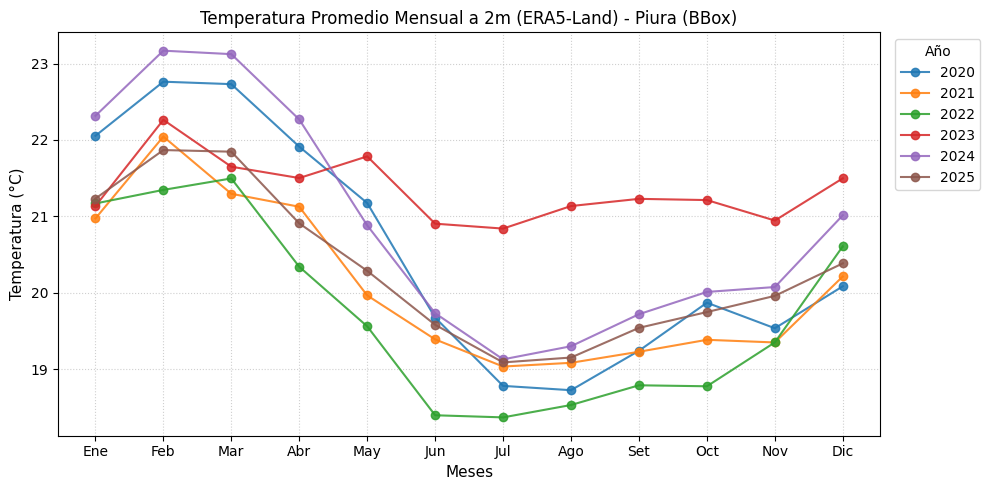

In [ ]:
fig_era5, ax_era5 = plt.subplots(figsize=(10, 5)) # Crea la figura

# Iteramos sobre cada año (cada columna) para trazar su respectiva línea
for col in df_pivot_era5.columns:
    ax_era5.plot(df_pivot_era5.index, df_pivot_era5[col], marker='o', label=str(col), linewidth=1.5, alpha=0.85)
    # Dibuja la línea con marcadores circulares y cierta transparencia

# Personalización de los ejes y títulos del gráfico
nombres_meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Set', 'Oct', 'Nov', 'Dic'] # Lista con las abreviaturas de los meses
ax_era5.set_xticks(range(1, 13)) # Define que el eje X tendrá 12 marcas exactas
ax_era5.set_xticklabels(nombres_meses) # Intercambia los números por los textos (Ene, Feb, Mar...)
ax_era5.set_title('Temperatura Promedio Mensual a 2m (ERA5-Land) - Piura (BBox)', fontsize=12) # Título principal del gráfico
ax_era5.set_xlabel('Meses', fontsize=11) # Nombre de eje inferior
ax_era5.set_ylabel('Temperatura (°C)', fontsize=11) # Nombre de eje lateral
ax_era5.grid(True, linestyle=':', alpha=0.6) # Activa guías visuales punteadas en el fondo
ax_era5.legend(title='Año', bbox_to_anchor=(1.01, 1), loc='upper left') # Mueve la leyenda fuera del área de las líneas
plt.tight_layout() # Ajusta la imagen
plt.show() # Dibuja el gráfico

/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_1_states_provinces_lakes.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


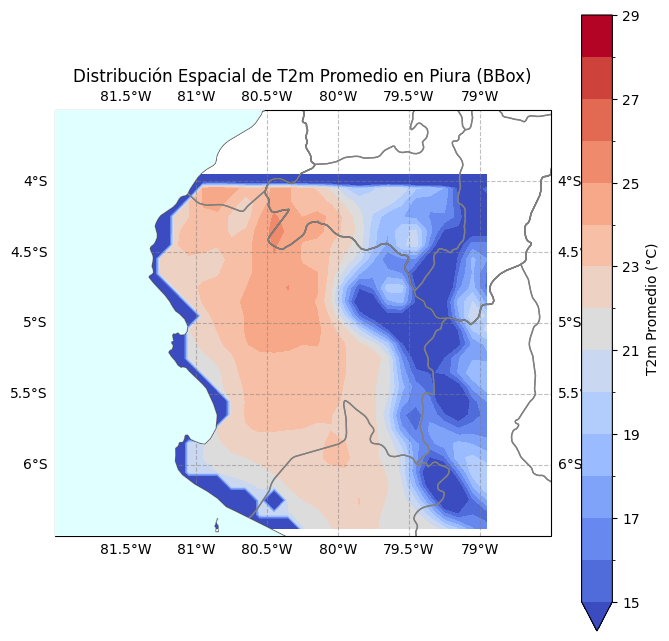

In [ ]:
# Promediamos toda la serie histórica y la cortamos a la forma de nuestro BBox
img_promedio_era5 = era5_mensual.mean().subtract(273.15).clip(roi_bbox_era5) # Calcula la imagen promedio, la pasa a Celsius y la recorta a la zona de estudio

# Descargamos el GeoTIFF temporalmente
url_era5 = img_promedio_era5.getDownloadURL({
    "region": roi_bbox_era5, # Especifica el polígono de descarga
    "scale": 11132, # Mantiene la resolución original de ERA5-Land
    "crs": "EPSG:4326", # Define el sistema de coordenadas geográficas estándar (Lat/Lon)
    "format": "GEO_TIFF" # Pide a los servidores que empaqueten los datos en formato GeoTIFF
})
r_era5 = requests.get(url_era5, timeout=300) # Realiza la petición a la URL generada para bajar el archivo
with open("t2m_piura_era5.tif", "wb") as f_era5: # Crea un archivo local en modo de escritura binaria ("wb")
    f_era5.write(r_era5.content) # Guarda todos los datos descargados dentro de ese archivo tif

# Leemos el GeoTIFF con Rioxarray y lo preparamos para Cartopy
tif_era5 = rioxarray.open_rasterio("t2m_piura_era5.tif").squeeze("band", drop=True) # Abre el raster local y aplana las dimensiones vacías para evitar problemas de ploteo
fig_mapa_era5, ax_mapa_era5 = plt.subplots(figsize=(8, 8), subplot_kw={'projection': ccrs.PlateCarree()}) # Crea el lienzo del mapa utilizando la proyección PlateCarree

# Graficamos la matriz de datos con contornos de colores
tif_era5.plot.contourf(ax=ax_mapa_era5, transform=ccrs.PlateCarree(), levels=np.arange(15, 30, 1), cmap='coolwarm', cbar_kwargs={'label': 'T2m Promedio (°C)'}) # Mapea los valores de temperatura usando una paleta cálida-fría
ax_mapa_era5.set_extent([-82, -78.5, -6.5, -3.5], crs=ccrs.PlateCarree()) # Hace un 'zoom' o recorte visual en las coordenadas indicadas

# Agregamos los elementos cartográficos específicos (Features)
ax_mapa_era5.add_feature(cfeature.COASTLINE) # Agrega línea de costa
ax_mapa_era5.add_feature(cfeature.BORDERS, linestyle='-') # Agrega fronteras internacionales con línea sólida
ax_mapa_era5.add_feature(cfeature.STATES, edgecolor="gray") # Agrega las fronteras de departamentos/estados en color gris
ax_mapa_era5.add_feature(cfeature.OCEAN, facecolor='lightcyan', zorder=10) # Dibuja el océano de un color cian claro por encima del raster (zorder=10)

ax_mapa_era5.gridlines(draw_labels=True, color='gray', alpha=0.5, linestyle='--') # Agrega las líneas de paralelos y meridianos mostrando sus coordenadas numéricas
ax_mapa_era5.set_title('Distribución Espacial de T2m Promedio en Piura (BBox)') # Agrega el título al mapa
plt.show() # Muestra el mapa en pantalla

### Variable 1.2. : Temperatura superficial terrestre - Landsat 8/9

In [ ]:
# 1 Definimos la geometría para Landsat usando las mismas coordenadas
bbox_piura = [-81.4, -6.1, -79.2, -4.1] # Coordenadas geográficas Piura
roi_bbox_landsat = ee.Geometry.Rectangle(bbox_piura)

# 2 Función para aplicar el factor de escala térmico oficial de Landsat (Colección 2)
def activar_escala_landsat(img):
    # Toma los datos crudos de la banda térmica (ST_B10), los multiplica por el factor de calibración y les suma un offset para convertirlos a Kelvin reales
    temp_k = img.select('ST_B10').multiply(0.00341802).add(149.0)
    # Resta 273.15 para pasar la temperatura a Celsius inmediatamente y la renombra
    temp_c = temp_k.subtract(273.15).rename('LST_Celsius')
    # Devuelve la imagen satelital original pero con esta nueva banda térmica en Celsius agregada
    return img.addBands(temp_c)

# 3 Cargar y combinar las colecciones de Landsat 8 y 9
l8 = ee.ImageCollection("LANDSAT/LC08/C02/T1_L2") # Catálogo Landsat 8
l9 = ee.ImageCollection("LANDSAT/LC09/C02/T1_L2") # Catálogo Landsat 9

# Combinamos ambas misiones, filtramos por área, fecha y descartamos nubes densas
landsat_combinado = (l8.merge(l9) # Une matemáticamente las dos colecciones para tener mayor frecuencia temporal
                     .filterBounds(roi_bbox_landsat) # Selecciona solo las imágenes que toquen nuestro rectángulo en Piura
                     .filterDate("2020-01-01", "2025-12-31") # Filtra el lapso de tiempo requerido
                     .filter(ee.Filter.lt("CLOUD_COVER", 20)) # Filtra y elimina las imágenes que tengan 20% o más de nubosidad global
                     .map(activar_escala_landsat)) # Aplica la función matemática de temperatura vista arriba a todas las fotos

# 4 Función para extraer la media espacial agrupando todas las imágenes disponibles por mes
meses_str = pd.date_range("2020-01-01", "2025-12-31", freq="MS").strftime("%Y-%m-%d").tolist() # Crea una lista de Python con las fechas del día 1 de cada mes
ee_meses_landsat = ee.List(meses_str) # Pasa la lista de Python al entorno de servidor de Earth Engine

def calcular_media_mensual_landsat(fecha_str):
    fecha = ee.Date(fecha_str) # Transforma el texto a un objeto fecha de EE
    # Filtra la gran colección combinada para que deje solo las imágenes tomadas durante ese mes específico
    coleccion_mes = landsat_combinado.filterDate(fecha, fecha.advance(1, 'month'))

    # Condicional: Si hay fotos útiles en el mes, se promedian. Si el mes estuvo completamente nublado, devuelve una imagen vacía
    img_mensual = ee.Image(ee.Algorithms.If(
        coleccion_mes.size().gt(0), # Condición: ¿La colección tiene más de 0 imágenes?
        coleccion_mes.mean(), # Verdadero: calcula la imagen promedio del mes
        ee.Image.constant(0).rename('LST_Celsius').selfMask() # Falso: genera una imagen nula transparente
    ))

    # Calcula el valor único espacial de esa imagen mensual promediada
    media = img_mensual.reduceRegion(
        reducer=ee.Reducer.mean(), # Usa la media matemática espacial
        geometry=roi_bbox_landsat, # Aplica esto sobre Piura
        scale=1000, # Disminuye la resolución de Landsat (30m) a 1km para que no colapse el cálculo en la memoria
        maxPixels=1e9 # Expande el límite de píxeles máximos
    ).get("LST_Celsius") # Obtiene solo el resultado de la banda térmica

    return ee.Feature(None, {'date': fecha_str, 'lst_C': media}) # Devuelve un paquete con la fecha y la temperatura mensual calculada

# 5 Ejecución y conversión a DataFrame tabular
# Llama la función iterativamente sobre todos los meses, filtra vacíos y los trae de los servidores de Google al Colab
features_landsat = ee.FeatureCollection(ee_meses_landsat.map(calcular_media_mensual_landsat)).filter(ee.Filter.notNull(['lst_C'])).getInfo()['features']
df_landsat = pd.DataFrame([f['properties'] for f in features_landsat]) # Forma el DataFrame desde la respuesta JSON recibida

# 6 Procesamos las variables temporales extraídas para estructurar el gráfico
df_landsat['fecha'] = pd.to_datetime(df_landsat['date']) # Formatea el texto a una estructura cronológica
df_landsat['año'] = df_landsat['fecha'].dt.year # Crea una columna exclusivamente con el número de año
df_landsat['mes'] = df_landsat['fecha'].dt.month # Crea una columna con el número del mes (1 a 12)

# 7 Pivotamos los datos: X = meses, Columnas = años
df_pivot_landsat = df_landsat.pivot(index='mes', columns='año', values='lst_C') # Reorganiza la tabla para que Matplotlib trace fácilmente líneas por separado

# 8 Exportamos el DataFrame en crudo a Google Drive para Landsat
# Se asume que drive ya está montado, procedemos a guardar el archivo CSV con nombre diferenciado
df_landsat.to_csv('/content/drive/My Drive/Landsat_LST_Piura.csv', index=False) # Guarda sin columna de enumeración
print("Archivo crudo Landsat guardado exitosamente en Google Drive.")


Archivo crudo Landsat guardado exitosamente en Google Drive.


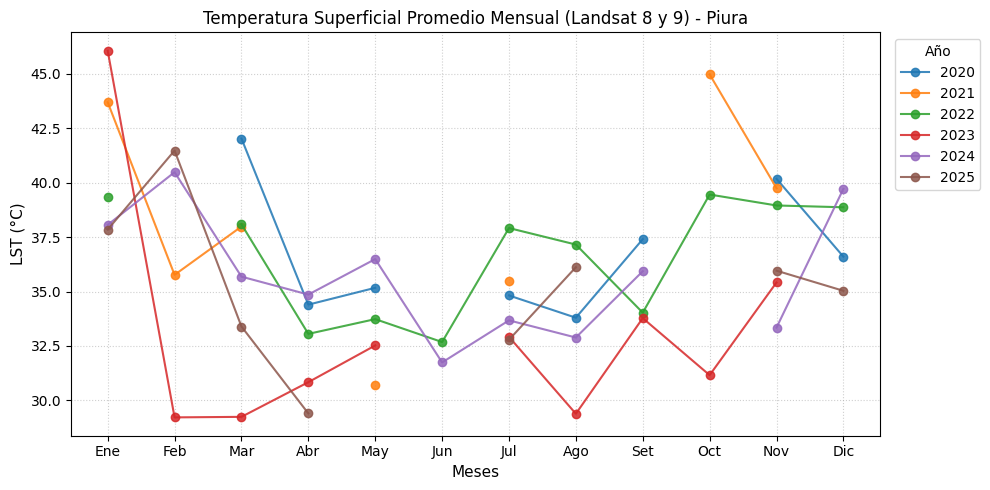

In [ ]:
fig_landsat, ax_landsat = plt.subplots(figsize=(10, 5)) # Crea la figura

# Bucle para dibujar una línea de color distinta para cada año del pivote
for col in df_pivot_landsat.columns:
    ax_landsat.plot(df_pivot_landsat.index, df_pivot_landsat[col], marker='o', label=str(col), linewidth=1.5, alpha=0.85)
    # Plotea la línea conectando los meses de ese año

# Personalización de los ejes y títulos del gráfico
ax_landsat.set_xticks(range(1, 13)) # Define que el eje X tendrá 12 marcas exactas
ax_landsat.set_xticklabels(nombres_meses) # Intercambia los números por los textos (Ene, Feb, Mar...)
ax_landsat.set_title('Temperatura Superficial Promedio Mensual (Landsat 8 y 9) - Piura', fontsize=12) # Título principal del gráfico
ax_landsat.set_xlabel('Meses', fontsize=11) # Nombre de eje inferior
ax_landsat.set_ylabel('LST (°C)', fontsize=11) # Nombre de eje lateral
ax_landsat.grid(True, linestyle=':', alpha=0.6) # Activa guías visuales punteadas en el fondo
ax_landsat.legend(title='Año', bbox_to_anchor=(1.01, 1), loc='upper left') # Mueve la leyenda fuera del área de las líneas
plt.tight_layout() # Ajusta la imagen
plt.show() # Dibuja el gráfico

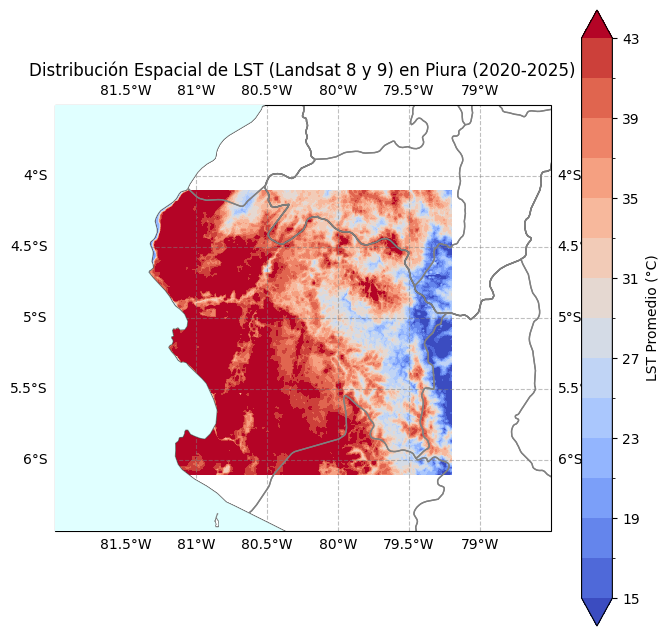

In [ ]:
# Promedia todas las imágenes de los 5 años en un único archivo espacial y lo corta al cuadrado
img_promedio_landsat = landsat_combinado.select('LST_Celsius').mean().clip(roi_bbox_landsat)

# Configura los parámetros de descarga del GeoTIFF
url_landsat = img_promedio_landsat.getDownloadURL({
    "region": roi_bbox_landsat, # Le dice qué polígono descargar
    "scale": 1000, # Asigna resolución de 1km
    "crs": "EPSG:4326", # Define coordenadas Lat/Lon
    "format": "GEO_TIFF" # Formato tif
})
r_landsat = requests.get(url_landsat, timeout=300) # Descarga la información a memoria
with open("lst_landsat_piura.tif", "wb") as f_landsat: # Inicializa la creación del archivo físico
    f_landsat.write(r_landsat.content) # Guarda los datos descargados en disco

# Carga la imagen al entorno usando Rioxarray
tif_landsat = rioxarray.open_rasterio("lst_landsat_piura.tif").squeeze("band", drop=True) # Lee el tif y quita metadatos dimensionales no necesarios
fig_mapa_landsat, ax_mapa_landsat = plt.subplots(figsize=(8, 8), subplot_kw={'projection': ccrs.PlateCarree()}) # Establece la proyección para el mapa

# Grafica la matriz térmica usando un mapa de calor
tif_landsat.plot.contourf(ax=ax_mapa_landsat, transform=ccrs.PlateCarree(), levels=np.arange(15, 45, 2), cmap='coolwarm', cbar_kwargs={'label': 'LST Promedio (°C)'}) # Establece límites térmicos (15-45°C) y la barra guía
ax_mapa_landsat.set_extent([-82, -78.5, -6.5, -3.5], crs=ccrs.PlateCarree()) # Limita los bordes visibles del mapa

# Agrega las guías vectoriales (Cartopy Features)
ax_mapa_landsat.add_feature(cfeature.COASTLINE) # Agrega línea de costa
ax_mapa_landsat.add_feature(cfeature.BORDERS, linestyle='-') # Agrega fronteras internacionales
ax_mapa_landsat.add_feature(cfeature.STATES, edgecolor="gray") # Agrega divisiones departamentales/estatales
ax_mapa_landsat.add_feature(cfeature.OCEAN, facecolor='lightcyan', zorder=10) # Enmascara visualmente el océano

ax_mapa_landsat.gridlines(draw_labels=True, color='gray', alpha=0.5, linestyle='--') # Agrega las guías de coordenadas geográficas
ax_mapa_landsat.set_title('Distribución Espacial de LST (Landsat 8 y 9) en Piura (2020-2025)') # Agregamos el título al gráfico
plt.show() #Mostramos el gráfico

### Variable 2.1.: Índice Oceánico de El Niño

In [ ]:
url_oni = 'https://drive.google.com/uc?export=download&id=15PTN3-30z6HVUZEoyo0pRbARnuim7moN'
df_oni_raw = pd.read_csv(url_oni)

In [ ]:
meses_oni_num = {  # Diccionario para convertir temporadas a número de mes
    'DJF': 1, 'JFM': 2, 'FMA': 3, 'MAM': 4,'AMJ': 5, 'MJJ': 6, 'JJA': 7, 'JAS': 8,'ASO': 9, 'SON': 10, 'OND': 11, 'NDJ': 12}

nombres_meses = {  # Diccionario para convertir número de mes a texto
    1: 'Ene', 2: 'Feb', 3: 'Mar', 4: 'Abr', 5: 'May', 6: 'Jun', 7: 'Jul', 8: 'Ago', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dic'}

In [ ]:
df_oni = pd.melt(df_oni_raw, id_vars=['Year'], var_name='Trimestre', value_name='ONI')  # Transforma columnas de trimestres a filas
df_oni['Mes_Num'] = df_oni['Trimestre'].map(meses_oni_num)  # Crea columna con número del mes
df_oni['Mes'] = df_oni['Mes_Num'].map(nombres_meses)  # Crea columna con nombre del mes
df_oni['Fecha'] = pd.to_datetime(df_oni['Year'].astype(str) + '-' + df_oni['Mes_Num'].astype(str) + '-01')  # Crea objeto Fecha para graficar

In [ ]:
df_oni_2020_2025 = df_oni[(df_oni['Year'] >= 2020) & (df_oni['Year'] <= 2025)].sort_values('Fecha').reset_index(drop=True)  # Filtra entre 2020 y 2025

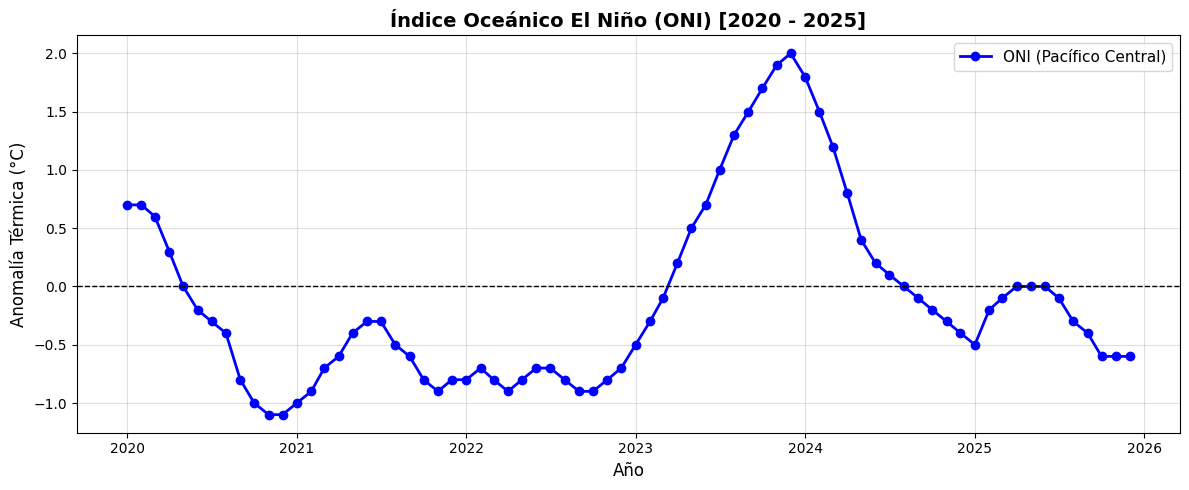

In [ ]:
plt.figure(figsize=(12, 5))  # Define el tamaño de la figura
plt.plot(df_oni_2020_2025['Fecha'], df_oni_2020_2025['ONI'], label='ONI (Pacífico Central)', color='blue', linewidth=2, marker='o')  # Dibuja la línea del ONI
plt.axhline(0, color='black', linewidth=1, linestyle='--')  # Dibuja la línea de referencia en cero
plt.title('Índice Oceánico El Niño (ONI) [2020 - 2025]', fontsize=14, fontweight='bold')  # Añade título al gráfico
plt.xlabel('Año', fontsize=12)  # Define etiqueta del eje X
plt.ylabel('Anomalía Térmica (°C)', fontsize=12)  # Define etiqueta del eje Y
plt.legend(loc='upper right', fontsize=11)  # Muestra la leyenda del gráfico
plt.grid(True, alpha=0.4)  # Activa la cuadrícula de fondo
plt.tight_layout()  # Ajusta los márgenes del gráfico
plt.show()  # Muestra el gráfico en pantalla

In [ ]:
df_oni_export = df_oni_2020_2025[['Year', 'Mes', 'Mes_Num', 'ONI']]
ruta_oni = '/content/drive/MyDrive/ONI_2020_2025.csv'  # Define la ruta de destino en Drive
df_oni_export.to_csv(ruta_oni, index=False)
print("Archivo ONI_2020_2025 guardado exitosamente en Google Drive.")

Archivo ONI_2020_2025 guardado exitosamente en Google Drive.


### Variable 2.2.: Índice Costero El Niño

In [ ]:
url_icen = 'https://drive.google.com/uc?export=download&id=1bBe2ako9Qgd-qqjD2KwtzwiALGeacKjP'
df_icen_raw = pd.read_csv(url_icen)

In [ ]:
df_icen = df_icen_raw.rename(columns={'yy': 'Year', 'mm': 'Mes_Num'})  # Estandariza los nombres de columnas yy y mm
df_icen['Mes'] = df_icen['Mes_Num'].map(nombres_meses)  # Crea columna con nombre del mes
df_icen['Fecha'] = pd.to_datetime(df_icen['Year'].astype(str) + '-' + df_icen['Mes_Num'].astype(str) + '-01')  # Crea objeto Fecha para graficar

In [ ]:
df_icen_2020_2025 = df_icen[(df_icen['Year'] >= 2020) & (df_icen['Year'] <= 2025)].sort_values('Fecha').reset_index(drop=True)  # Filtra entre 2020 y 2025

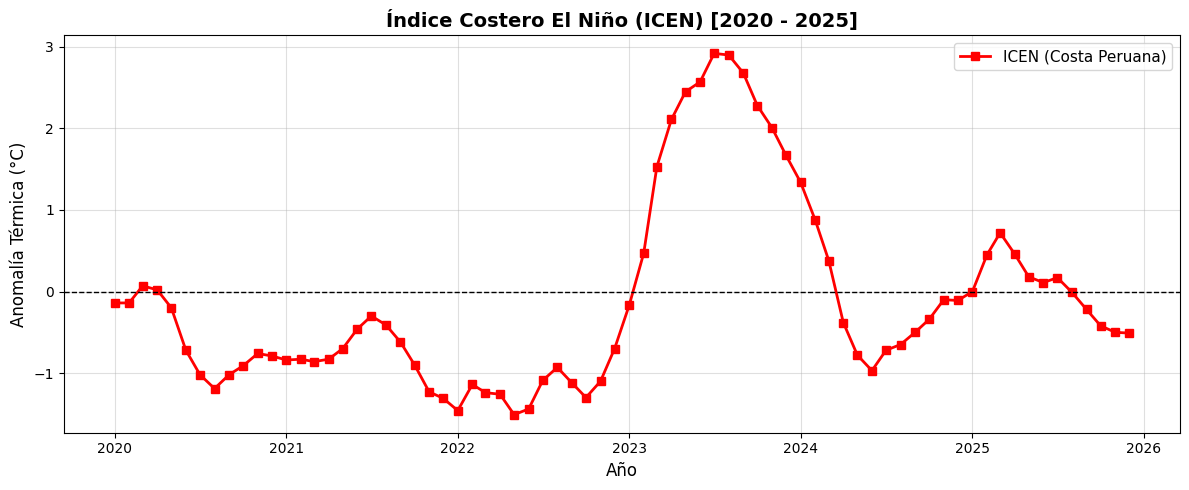

In [ ]:
plt.figure(figsize=(12, 5))  # Define el tamaño de la figura
plt.plot(df_icen_2020_2025['Fecha'], df_icen_2020_2025['ICEN'], label='ICEN (Costa Peruana)', color='red', linewidth=2, marker='s')  # Dibuja la línea del ICEN
plt.axhline(0, color='black', linewidth=1, linestyle='--')  # Dibuja la línea de referencia en cero
plt.title('Índice Costero El Niño (ICEN) [2020 - 2025]', fontsize=14, fontweight='bold')  # Añade título al gráfico
plt.xlabel('Año', fontsize=12)  # Define etiqueta del eje X
plt.ylabel('Anomalía Térmica (°C)', fontsize=12)  # Define etiqueta del eje Y
plt.legend(loc='upper right', fontsize=11)  # Muestra la leyenda del gráfico
plt.grid(True, alpha=0.4)  # Activa la cuadrícula de fondo
plt.tight_layout()  # Ajusta los márgenes del gráfico
plt.show()  # Muestra el gráfico en pantalla

In [ ]:
df_icen_export = df_icen_2020_2025[['Year', 'Mes', 'Mes_Num', 'ICEN']]
ruta_icen = '/content/drive/MyDrive/ICEN_2020_2025.csv'  # Define la ruta de destino en Drive
df_icen_export.to_csv(ruta_icen, index=False)
print("Archivo ICEN_2020_2025 guardado exitosamente en Google Drive.")

Archivo ICEN_2020_2025 guardado exitosamente en Google Drive.


**Bibliografía:**

Climate Prediction Center. (s. f.). *Cold & warm episodes by season (ERSSTv6).* National Oceanic and Atmospheric Administration. Recuperado el 14 de octubre de 2026, de https://cpc.ncep.noaa.gov/products/analysis_monitoring/enso/oni/v6/


Comisión Multisectorial encargada del Estudio Nacional del Fenómeno «El Niño». (2024). *Definición operacional de los eventos El Niño costero y La Niña costera en el Perú* (Nota Técnica ENFEN 01-2024). https://enfen.imarpe.gob.pe/download/nota-tecnica-enfen-01-2024-definicion-operacional-de-los-eventos-el-nino-costero-y-la-nina-costera-en-el-peru/?wpdmdl=1905&ind=1733921744133


Instituto Geofísico del Perú. (2024). *Informe técnico Nº PpR/El Niño-IGP/2024-05.* https://repositorio.igp.gob.pe/bitstreams/bc31de02-1c79-476d-a28f-c48a6a02e2c0/download


Rodríguez, I., Villarreal, E. y Acosta, J. (2011). *Memoria sobre la geología económica de la región Piura.* Instituto Geológico, Minero y Metalúrgico. https://portal.ingemmet.gob.pe/documents/73138/468768/2011_GE33_Memoria_Geologia_Economica_Piura.pdf/710d21b0-bf67-4326-869a-ecfc88eec267


Takahashi, K. (2004). *The atmospheric circulation associated with extreme rainfall events in Piura, Peru, during the 1997–1998 and 2002 El Niño events. Annales Geophysicae, 22(11)*, 3917–3926. https://doi.org/10.5194/angeo-22-3917-2004



Takahashi, K., Aliaga-Nestares, V., Avalos, G., Bouchon, M., Castro, A., Cruzado, L., Dewitte, B., Gutiérrez, D., Lavado-Casimiro, W., Marengo, J., Martínez, A. G., Mosquera Vásquez, K. y Quispe, N. (2018). The 2017 coastal El Niño. *Bulletin of the American Meteorological Society*, 99(8), S210–S242. https://doi.org/10.1175/2018BAMSStateoftheClimate.1



Yglesias-González, M., Valdés-Velásquez, A., Hartinger, S. M., Takahashi, K., Salvatierra, G., Velarde, R., Contreras, A., Santa María, H., Romanello, M., Paz-Soldán, V., Bazo, J. y Lescano, A. G. (2023). Reflections on the impact and response to the Peruvian 2017 coastal El Niño event: Looking to the past to prepare for the future. *PLOS ONE*, 18(9), Artículo e0290767. https://doi.org/10.1371/journal.pone.0290767

## **Enlaces**

[Enlace Drive con datos crudos](https://drive.google.com/drive/folders/1ij63gMxIznzkXioFCEjUQID0N6r0wCm7?usp=sharing)

[Enlace al repositorio GitHub](https://github.com/k-montoya/1GEO20_Grupo-3)